# DQN on Atari Breakout

This notebook implements a Deep Q-Network (DQN) agent for the Atari Breakout environment using PyTorch and Gymnasium/ALE.

The project includes:

1. Atari environment setup and preprocessing
2. DQN neural network
3. Experience replay buffer
4. Target network
5. Epsilon-greedy exploration
6. DQN training
7. Reward, loss, Q-value, and epsilon tracking
8. Evaluation runs
9. Gameplay GIF and snapshots
10. Hyperparameter experimentation

> Recommended: Run this notebook in Google Colab with **GPU** enabled.

## Install Required Libraries

Run this cell first. If Colab asks you to restart the runtime after installation, restart it and continue from the imports cell.

In [1]:
!pip install -q "gymnasium[atari]>=1.0" "ale-py>=0.10" opencv-python-headless imageio

## Import Libraries

In [2]:
import os
import random
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v2 as imageio

import gymnasium as gym
import ale_py

import torch
import torch.nn as nn
import torch.optim as optim

gym.register_envs(ale_py)

print("Gymnasium version:", gym.__version__)
print("PyTorch version:", torch.__version__)

Gymnasium version: 1.3.0
PyTorch version: 2.11.0+cu128


## Random Seed and Device

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


## Hyperparameters

These values can be changed to compare how DQN behavior changes.

For a fair comparison, change one or two values at a time and retrain the agent from scratch.

In [4]:
ENV_NAME = "ALE/Breakout-v5"

# Image preprocessing
SCREEN_SIZE = 84
FRAME_STACK = 4
FRAME_SKIP = 4

# DQN hyperparameters
LEARNING_RATE = 0.0001
GAMMA = 0.99
BATCH_SIZE = 32

# Replay memory
REPLAY_BUFFER_SIZE = 20_000
LEARNING_STARTS = 5_000

# Training frequency
TRAIN_FREQUENCY = 4

# Target network
TARGET_UPDATE_FREQUENCY = 5_000

# Epsilon-greedy exploration
EPSILON_START = 1.0
EPSILON_END = 0.10
EPSILON_DECAY_STEPS = 100_000

# Training duration
MAX_EPISODES = 1000
MAX_TOTAL_STEPS = 10000

# Save checkpoints
CHECKPOINT_FREQUENCY = 50_000

# Plotting
MOVING_AVERAGE_WINDOW = 20

# Standard DQN reward clipping
CLIP_REWARDS = True

OUTPUT_DIR = "dqn_breakout_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Environment:", ENV_NAME)
print("Learning Rate:", LEARNING_RATE)
print("Gamma:", GAMMA)
print("Batch Size:", BATCH_SIZE)
print("Replay Buffer Size:", REPLAY_BUFFER_SIZE)
print("Target Update Frequency:", TARGET_UPDATE_FREQUENCY)
print("Epsilon Start:", EPSILON_START)
print("Epsilon End:", EPSILON_END)
print("Epsilon Decay Steps:", EPSILON_DECAY_STEPS)
print("Maximum Training Steps:", MAX_TOTAL_STEPS)

Environment: ALE/Breakout-v5
Learning Rate: 0.0001
Gamma: 0.99
Batch Size: 32
Replay Buffer Size: 20000
Target Update Frequency: 5000
Epsilon Start: 1.0
Epsilon End: 0.1
Epsilon Decay Steps: 100000
Maximum Training Steps: 10000


## Inspect the Original Breakout Environment

The raw Atari observation is an RGB frame. We inspect it before applying preprocessing.

Original observation shape: (210, 160, 3)
Original observation dtype: uint8
Action space: Discrete(4)
Actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']


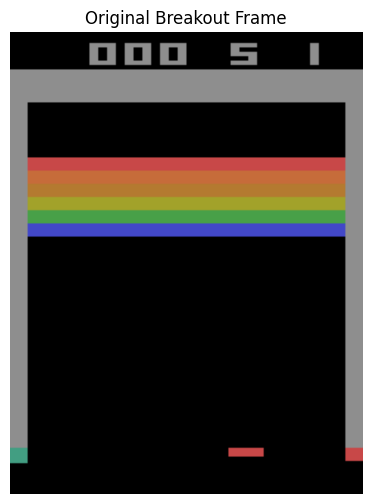

In [5]:
raw_env = gym.make(
    ENV_NAME,
    frameskip=1,
    repeat_action_probability=0.0,
    full_action_space=False,
    render_mode="rgb_array"
)

raw_state, raw_info = raw_env.reset(seed=SEED)

print("Original observation shape:", raw_state.shape)
print("Original observation dtype:", raw_state.dtype)
print("Action space:", raw_env.action_space)
print("Actions:", raw_env.unwrapped.get_action_meanings())

plt.figure(figsize=(6, 6))
plt.imshow(raw_state)
plt.title("Original Breakout Frame")
plt.axis("off")
plt.show()

raw_env.close()



## Breakout Auto-Fire Wrapper

Breakout requires the FIRE action to start the ball. This wrapper automatically fires at the beginning of an episode and after a life is lost.

In [6]:
class BreakoutAutoFire(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        self.fire_action = 1
        self.previous_lives = None

    def reset(self, **kwargs):
        observation, info = self.env.reset(**kwargs)

        observation, reward, terminated, truncated, info = self.env.step(
            self.fire_action
        )

        if terminated or truncated:
            observation, info = self.env.reset(**kwargs)
            observation, reward, terminated, truncated, info = self.env.step(
                self.fire_action
            )

        self.previous_lives = info.get("lives", None)
        return observation, info

    def step(self, action):
        observation, reward, terminated, truncated, info = self.env.step(action)

        current_lives = info.get("lives", self.previous_lives)

        if (
            self.previous_lives is not None
            and current_lives is not None
            and current_lives < self.previous_lives
            and current_lives > 0
            and not terminated
            and not truncated
        ):
            (
                observation,
                fire_reward,
                fire_terminated,
                fire_truncated,
                fire_info
            ) = self.env.step(self.fire_action)

            reward += fire_reward
            terminated = terminated or fire_terminated
            truncated = truncated or fire_truncated
            info = fire_info
            current_lives = info.get("lives", current_lives)

        self.previous_lives = current_lives

        return observation, reward, terminated, truncated, info

## Create the Preprocessed Atari Environment

Preprocessing used:

- Frame skipping
- Max pooling
- Grayscale conversion
- Resize to 84 × 84
- Stack 4 consecutive frames
- Pixel normalization inside the neural network

In [7]:
def make_atari_env(render_mode=None):
    # frameskip=1 because AtariPreprocessing performs the frame skipping
    env = gym.make(
        ENV_NAME,
        frameskip=1,
        repeat_action_probability=0.0,
        full_action_space=False,
        render_mode=render_mode
    )

    env = gym.wrappers.AtariPreprocessing(
        env,
        noop_max=30,
        frame_skip=FRAME_SKIP,
        screen_size=SCREEN_SIZE,
        terminal_on_life_loss=False,
        grayscale_obs=True,
        grayscale_newaxis=False,
        scale_obs=False
    )

    env = BreakoutAutoFire(env)

    env = gym.wrappers.FrameStackObservation(
        env,
        stack_size=FRAME_STACK
    )

    return env


env = make_atari_env()

state, info = env.reset(seed=SEED)

print("Processed observation shape:", np.asarray(state).shape)
print("Processed observation dtype:", np.asarray(state).dtype)
print("Action space:", env.action_space)
print("Action meanings:", env.unwrapped.get_action_meanings())

Processed observation shape: (4, 84, 84)
Processed observation dtype: uint8
Action space: Discrete(4)
Action meanings: ['NOOP', 'FIRE', 'RIGHT', 'LEFT']



## Display a Preprocessed Frame

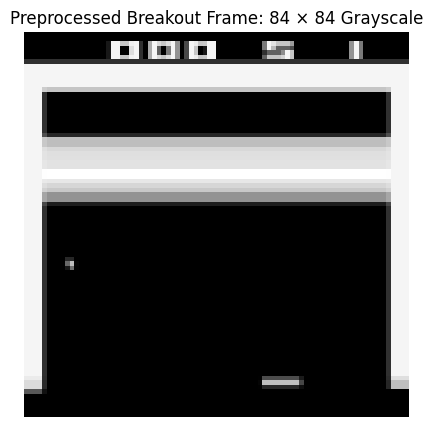

In [8]:
plt.figure(figsize=(5, 5))
plt.imshow(np.asarray(state)[-1], cmap="gray")
plt.title("Preprocessed Breakout Frame: 84 × 84 Grayscale")
plt.axis("off")
plt.show()

## Experience Replay Buffer

Each stored transition contains:

`(state, action, reward, next_state, done)`

In [9]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):
        state = np.asarray(state, dtype=np.uint8).copy()
        next_state = np.asarray(next_state, dtype=np.uint8).copy()

        self.buffer.append(
            (state, action, reward, next_state, done)
        )

    def sample(self, batch_size):
        samples = random.sample(self.buffer, batch_size)

        states, actions, rewards, next_states, dones = zip(*samples)

        states = np.stack(states)
        actions = np.array(actions)
        rewards = np.array(rewards, dtype=np.float32)
        next_states = np.stack(next_states)
        dones = np.array(dones, dtype=np.float32)

        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)


replay_buffer = ReplayBuffer(REPLAY_BUFFER_SIZE)

print("Replay buffer capacity:", REPLAY_BUFFER_SIZE)

Replay buffer capacity: 20000


## DQN Neural Network

A convolutional neural network processes the stacked Atari frames and outputs one Q-value for each possible action.

In [10]:
class DQN(nn.Module):
    def __init__(self, input_channels, number_of_actions):
        super().__init__()

        self.convolutional_layers = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=8, stride=4),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, stride=1),
            nn.ReLU()
        )

        with torch.no_grad():
            dummy_input = torch.zeros(
                1,
                input_channels,
                SCREEN_SIZE,
                SCREEN_SIZE
            )

            convolution_output = self.convolutional_layers(dummy_input)
            flattened_size = int(np.prod(convolution_output.shape[1:]))

        self.fully_connected_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flattened_size, 512),
            nn.ReLU(),
            nn.Linear(512, number_of_actions)
        )

    def forward(self, x):
        # Normalize pixel values from 0-255 to 0-1
        x = x.float() / 255.0

        x = self.convolutional_layers(x)
        q_values = self.fully_connected_layers(x)

        return q_values

##Test the DQN

In [11]:
number_of_actions = env.action_space.n

test_network = DQN(
    FRAME_STACK,
    number_of_actions
).to(device)

test_state = torch.tensor(
    np.asarray(state),
    dtype=torch.float32,
    device=device
).unsqueeze(0)

with torch.no_grad():
    test_q_values = test_network(test_state)

print("Number of actions:", number_of_actions)
print("Q-values:", test_q_values)
print("Q-value shape:", test_q_values.shape)

Number of actions: 4
Q-values: tensor([[-0.0186, -0.0232,  0.0289, -0.0316]], device='cuda:0')
Q-value shape: torch.Size([1, 4])


## DQN Agent

The agent contains:

- Policy network
- Target network
- Adam optimizer
- Huber loss
- Epsilon-greedy action selection
- DQN learning update

In [12]:
class DQNAgent:
    def __init__(
        self,
        state_channels,
        number_of_actions,
        learning_rate,
        device
    ):
        self.number_of_actions = number_of_actions
        self.device = device

        self.policy_network = DQN(
            state_channels,
            number_of_actions
        ).to(device)

        self.target_network = DQN(
            state_channels,
            number_of_actions
        ).to(device)

        self.target_network.load_state_dict(
            self.policy_network.state_dict()
        )
        self.target_network.eval()

        self.optimizer = optim.Adam(
            self.policy_network.parameters(),
            lr=learning_rate
        )

        self.loss_function = nn.SmoothL1Loss()

    def select_action(self, state, epsilon):
        # Exploration
        if random.random() < epsilon:
            return random.randrange(self.number_of_actions)

        # Exploitation
        state_tensor = torch.as_tensor(
            np.asarray(state),
            dtype=torch.float32,
            device=self.device
        ).unsqueeze(0)

        with torch.no_grad():
            q_values = self.policy_network(state_tensor)

        return q_values.argmax(dim=1).item()

    def learn(self, replay_buffer, batch_size, gamma):
        (
            states,
            actions,
            rewards,
            next_states,
            dones
        ) = replay_buffer.sample(batch_size)

        states = torch.as_tensor(
            states,
            dtype=torch.float32,
            device=self.device
        )

        actions = torch.as_tensor(
            actions,
            dtype=torch.long,
            device=self.device
        ).unsqueeze(1)

        rewards = torch.as_tensor(
            rewards,
            dtype=torch.float32,
            device=self.device
        )

        next_states = torch.as_tensor(
            next_states,
            dtype=torch.float32,
            device=self.device
        )

        dones = torch.as_tensor(
            dones,
            dtype=torch.float32,
            device=self.device
        )

        # Current Q(s,a)
        all_q_values = self.policy_network(states)

        current_q_values = all_q_values.gather(
            1,
            actions
        ).squeeze(1)

        # Target: r + gamma * max_a' Q_target(s',a')
        with torch.no_grad():
            next_q_values = (
                self.target_network(next_states)
                .max(dim=1)
                .values
            )

            target_q_values = (
                rewards
                + gamma
                * next_q_values
                * (1 - dones)
            )

        loss = self.loss_function(
            current_q_values,
            target_q_values
        )

        self.optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            self.policy_network.parameters(),
            max_norm=10.0
        )

        self.optimizer.step()

        average_q_value = (
            current_q_values
            .detach()
            .mean()
            .item()
        )

        return loss.item(), average_q_value

    def update_target_network(self):
        self.target_network.load_state_dict(
            self.policy_network.state_dict()
        )

    def save(self, file_path):
        torch.save(
            self.policy_network.state_dict(),
            file_path
        )

    def load(self, file_path):
        self.policy_network.load_state_dict(
            torch.load(
                file_path,
                map_location=self.device
            )
        )

        self.target_network.load_state_dict(
            self.policy_network.state_dict()
        )

##Create the DQN Agent

In [13]:
agent = DQNAgent(
    state_channels=FRAME_STACK,
    number_of_actions=env.action_space.n,
    learning_rate=LEARNING_RATE,
    device=device
)

print(agent.policy_network)

DQN(
  (convolutional_layers): Sequential(
    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
  )
  (fully_connected_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=4, bias=True)
  )
)


## Epsilon-Greedy Schedule

In [14]:
def calculate_epsilon(step):
    fraction = min(
        step / EPSILON_DECAY_STEPS,
        1.0
    )

    epsilon = (
        EPSILON_START
        + fraction * (EPSILON_END - EPSILON_START)
    )

    return epsilon


print("Step 0:", calculate_epsilon(0))
print("Step 25,000:", calculate_epsilon(25_000))
print("Step 50,000:", calculate_epsilon(50_000))
print("Step 100,000:", calculate_epsilon(100_000))
print("Step 200,000:", calculate_epsilon(200_000))

Step 0: 1.0
Step 25,000: 0.775
Step 50,000: 0.55
Step 100,000: 0.09999999999999998
Step 200,000: 0.09999999999999998


## Training Metric Storage

In [15]:
episode_rewards = []
episode_lengths = []
episode_epsilons = []

training_losses = []
loss_steps = []

average_q_values = []
q_value_steps = []

global_step = 0
best_moving_average = float("-inf")

##Train the DQN Agent

For a quick test, change:

##MAX_TOTAL_STEPS = 10_000

After confirming that the notebook runs correctly, increase it again for the final experiment.

In [16]:
for episode in range(1, MAX_EPISODES + 1):

    state, info = env.reset(seed=SEED + episode)

    episode_reward = 0.0
    episode_length = 0
    done = False

    while not done:

        # 1. Epsilon
        epsilon = calculate_epsilon(global_step)

        # 2. Select action
        action = agent.select_action(
            state,
            epsilon
        )

        # 3. Perform action
        (
            next_state,
            reward,
            terminated,
            truncated,
            info
        ) = env.step(action)

        done = terminated or truncated

        episode_reward += reward

        # 4. Reward clipping
        if CLIP_REWARDS:
            training_reward = np.sign(reward)
        else:
            training_reward = reward

        # 5. Store transition
        replay_buffer.add(
            state,
            action,
            training_reward,
            next_state,
            done
        )

        state = next_state

        global_step += 1
        episode_length += 1

        # 6. Train policy network
        if (
            len(replay_buffer) >= LEARNING_STARTS
            and global_step % TRAIN_FREQUENCY == 0
        ):
            loss, average_q = agent.learn(
                replay_buffer,
                BATCH_SIZE,
                GAMMA
            )

            training_losses.append(loss)
            loss_steps.append(global_step)

            average_q_values.append(average_q)
            q_value_steps.append(global_step)

        # 7. Target network update
        if (
            global_step % TARGET_UPDATE_FREQUENCY == 0
        ):
            agent.update_target_network()

            print(
                f"Target network updated at step {global_step}"
            )

        # 8. Save checkpoints
        if (
            global_step % CHECKPOINT_FREQUENCY == 0
        ):
            checkpoint_path = os.path.join(
                OUTPUT_DIR,
                f"dqn_breakout_step_{global_step}.pt"
            )

            agent.save(checkpoint_path)

            print(
                "Checkpoint saved:",
                checkpoint_path
            )

        if global_step >= MAX_TOTAL_STEPS:
            done = True

    episode_rewards.append(episode_reward)
    episode_lengths.append(episode_length)
    episode_epsilons.append(epsilon)

    recent_rewards = episode_rewards[
        -MOVING_AVERAGE_WINDOW:
    ]

    moving_average_reward = np.mean(
        recent_rewards
    )

    if moving_average_reward > best_moving_average:
        best_moving_average = moving_average_reward

        best_model_path = os.path.join(
            OUTPUT_DIR,
            "best_dqn_breakout.pt"
        )

        agent.save(best_model_path)

    print(
        f"Episode: {episode:4d} | "
        f"Steps: {global_step:7d} | "
        f"Reward: {episode_reward:7.2f} | "
        f"Moving Avg: {moving_average_reward:7.2f} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Buffer: {len(replay_buffer):5d}"
    )

    if global_step >= MAX_TOTAL_STEPS:
        print("\nMaximum training steps reached.")
        break

Episode:    1 | Steps:     314 | Reward:    4.00 | Moving Avg:    4.00 | Epsilon: 0.997 | Buffer:   314
Episode:    2 | Steps:     507 | Reward:    2.00 | Moving Avg:    3.00 | Epsilon: 0.995 | Buffer:   507
Episode:    3 | Steps:     627 | Reward:    0.00 | Moving Avg:    2.00 | Epsilon: 0.994 | Buffer:   627
Episode:    4 | Steps:     745 | Reward:    0.00 | Moving Avg:    1.50 | Epsilon: 0.993 | Buffer:   745
Episode:    5 | Steps:     864 | Reward:    0.00 | Moving Avg:    1.20 | Epsilon: 0.992 | Buffer:   864
Episode:    6 | Steps:    1057 | Reward:    2.00 | Moving Avg:    1.33 | Epsilon: 0.990 | Buffer:  1057
Episode:    7 | Steps:    1177 | Reward:    0.00 | Moving Avg:    1.14 | Epsilon: 0.989 | Buffer:  1177
Episode:    8 | Steps:    1297 | Reward:    0.00 | Moving Avg:    1.00 | Epsilon: 0.988 | Buffer:  1297
Episode:    9 | Steps:    1571 | Reward:    4.00 | Moving Avg:    1.33 | Epsilon: 0.986 | Buffer:  1571
Episode:   10 | Steps:    1691 | Reward:    0.00 | Moving Avg:  

##Close the Training Environment

In [17]:
env.close()

##Save the Final Model

In [18]:
final_model_path = os.path.join(
    OUTPUT_DIR,
    "final_dqn_breakout.pt"
)

agent.save(final_model_path)

print(
    "Final model saved:",
    final_model_path
)

Final model saved: dqn_breakout_outputs/final_dqn_breakout.pt


## Episode Metrics Table

In [19]:
episode_results = pd.DataFrame({
    "Episode": np.arange(
        1,
        len(episode_rewards) + 1
    ),
    "Reward": episode_rewards,
    "Episode_Length": episode_lengths,
    "Epsilon": episode_epsilons
})

episode_results["Moving_Average_Reward"] = (
    episode_results["Reward"]
    .rolling(
        window=MOVING_AVERAGE_WINDOW,
        min_periods=1
    )
    .mean()
)

episode_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "episode_metrics.csv"
    ),
    index=False
)

episode_results.tail(10)

,Episode,Reward,Episode_Length,Epsilon,Moving_Average_Reward
49,50,1.0,148,0.922852,1.50
50,51,0.0,118,0.921790,1.50
51,52,0.0,119,0.920719,1.45
52,53,1.0,167,0.919216,1.50
53,54,4.0,291,0.916597,1.65
54,55,1.0,148,0.915265,1.60
55,56,0.0,119,0.914194,1.35
56,57,1.0,165,0.912709,1.35
57,58,2.0,215,0.910774,1.35
58,59,0.0,85,0.910009,1.05


## Part 19: Training Metrics Table

In [20]:
training_results = pd.DataFrame({
    "Training_Step": loss_steps,
    "Loss": training_losses,
    "Average_Q_Value": average_q_values
})

training_results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "training_metrics.csv"
    ),
    index=False
)

training_results.head()

,Training_Step,Loss,Average_Q_Value
0,5000,0.000798,-0.012806
1,5004,0.000467,-0.004679
2,5008,0.000148,0.007569
3,5012,0.015673,0.013795
4,5016,0.000026,0.024012


## Episode Reward and Moving-Average Reward Plot

*   List item
*   List item



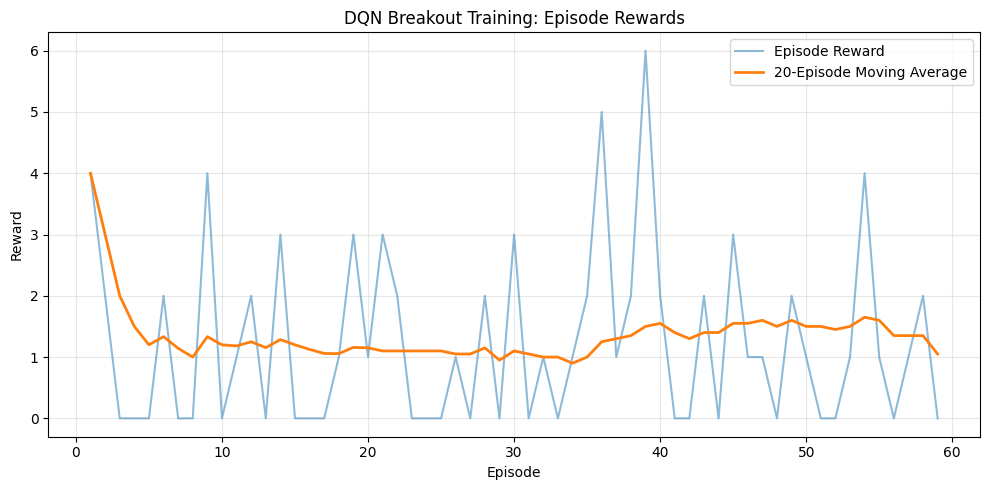

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(
    episode_results["Episode"],
    episode_results["Reward"],
    alpha=0.5,
    label="Episode Reward"
)

plt.plot(
    episode_results["Episode"],
    episode_results["Moving_Average_Reward"],
    linewidth=2,
    label=f"{MOVING_AVERAGE_WINDOW}-Episode Moving Average"
)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN Breakout Training: Episode Rewards")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "episode_rewards.png"
    ),
    dpi=300
)

plt.show()

## Training Loss Plot

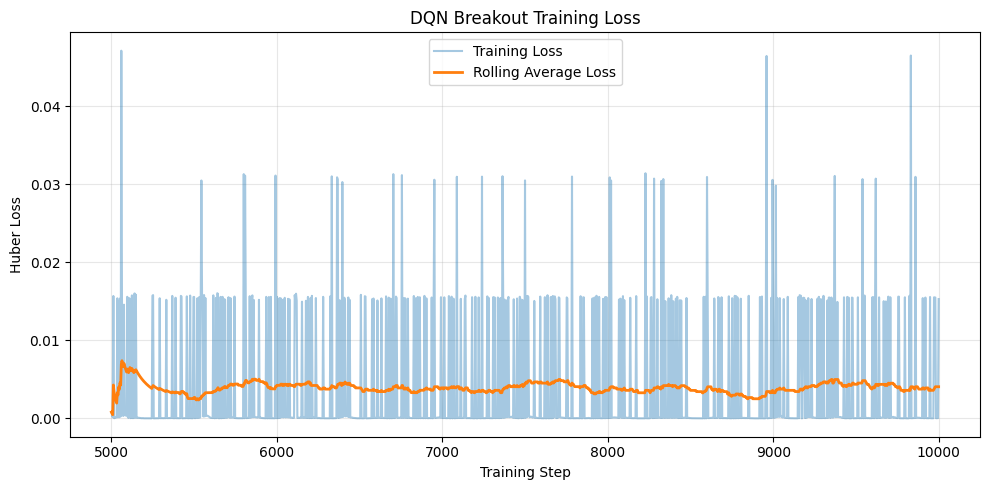

In [22]:
if len(training_results) > 0:

    plt.figure(figsize=(10, 5))

    plt.plot(
        training_results["Training_Step"],
        training_results["Loss"],
        alpha=0.4,
        label="Training Loss"
    )

    rolling_loss = (
        training_results["Loss"]
        .rolling(
            window=100,
            min_periods=1
        )
        .mean()
    )

    plt.plot(
        training_results["Training_Step"],
        rolling_loss,
        linewidth=2,
        label="Rolling Average Loss"
    )

    plt.xlabel("Training Step")
    plt.ylabel("Huber Loss")
    plt.title("DQN Breakout Training Loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "training_loss.png"
        ),
        dpi=300
    )

    plt.show()

else:
    print("No training loss data available yet.")

## Average Q-Value Plot

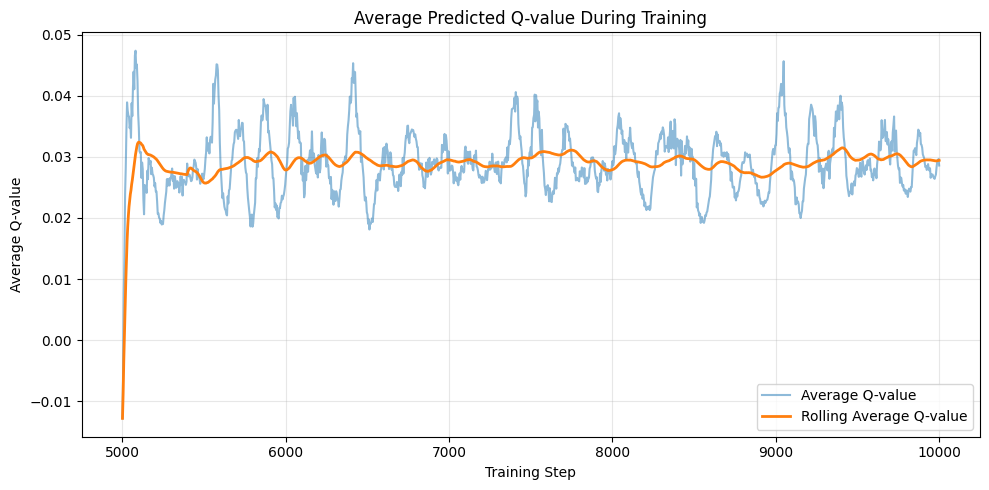

In [23]:
if len(training_results) > 0:

    plt.figure(figsize=(10, 5))

    plt.plot(
        training_results["Training_Step"],
        training_results["Average_Q_Value"],
        alpha=0.5,
        label="Average Q-value"
    )

    rolling_q = (
        training_results["Average_Q_Value"]
        .rolling(
            window=100,
            min_periods=1
        )
        .mean()
    )

    plt.plot(
        training_results["Training_Step"],
        rolling_q,
        linewidth=2,
        label="Rolling Average Q-value"
    )

    plt.xlabel("Training Step")
    plt.ylabel("Average Q-value")
    plt.title("Average Predicted Q-value During Training")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "q_value_trend.png"
        ),
        dpi=300
    )

    plt.show()

else:
    print("No Q-value data available yet.")

##Epsilon Decay Plot

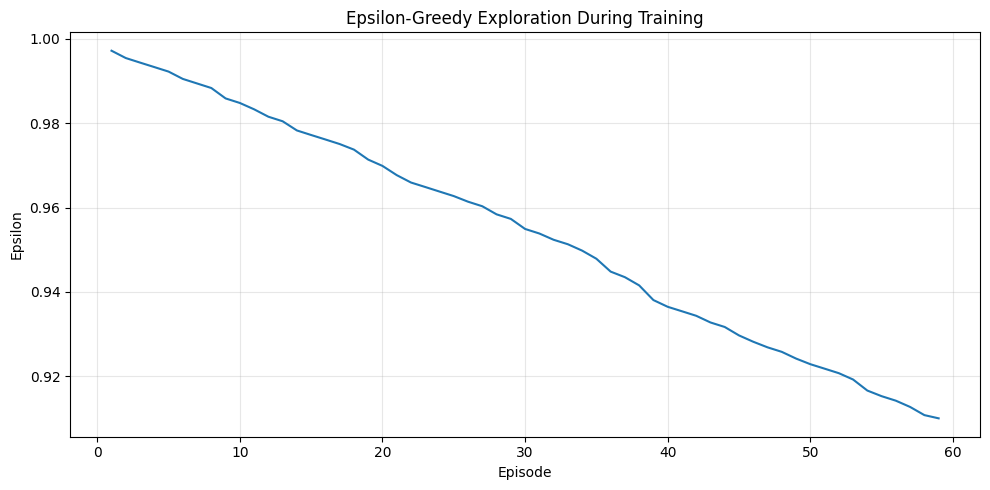

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    episode_results["Episode"],
    episode_results["Epsilon"]
)

plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon-Greedy Exploration During Training")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "epsilon_decay.png"
    ),
    dpi=300
)

plt.show()

##Training Summary

In [25]:
print("TRAINING SUMMARY")
print("------------------------------")

print(
    "Total Episodes:",
    len(episode_rewards)
)

print(
    "Total Environment Steps:",
    global_step
)

print(
    "Average Episode Reward:",
    np.mean(episode_rewards)
)

print(
    "Best Episode Reward:",
    np.max(episode_rewards)
)

print(
    f"Average Reward Last {MOVING_AVERAGE_WINDOW} Episodes:",
    np.mean(
        episode_rewards[
            -MOVING_AVERAGE_WINDOW:
        ]
    )
)

if len(training_losses) > 0:
    print(
        "Average Training Loss:",
        np.mean(training_losses)
    )

if len(average_q_values) > 0:
    print(
        "Final Average Q-value:",
        average_q_values[-1]
    )

TRAINING SUMMARY
------------------------------
Total Episodes: 59
Total Environment Steps: 10000
Average Episode Reward: 1.2372881355932204
Best Episode Reward: 6.0
Average Reward Last 20 Episodes: 1.05
Average Training Loss: 0.003882489674824454
Final Average Q-value: 0.028585918247699738


##Load the Best Model

In [26]:
best_model_path = os.path.join(
    OUTPUT_DIR,
    "best_dqn_breakout.pt"
)

agent.load(best_model_path)
agent.policy_network.eval()

print(
    "Loaded model:",
    best_model_path
)

Loaded model: dqn_breakout_outputs/best_dqn_breakout.pt


## Evaluate the Trained Agent

Evaluation uses `epsilon = 0.0`, so the agent chooses the action with the highest estimated Q-value.

In [27]:
def evaluate_agent(
    agent,
    number_of_episodes=10,
    save_gameplay=True
):
    evaluation_env = make_atari_env(
        render_mode="rgb_array"
    )

    evaluation_rewards = []
    gameplay_frames = []

    for episode in range(number_of_episodes):

        state, info = evaluation_env.reset(
            seed=1000 + episode
        )

        total_reward = 0.0
        terminated = False
        truncated = False
        step = 0

        while not (terminated or truncated):

            action = agent.select_action(
                state,
                epsilon=0.0
            )

            (
                state,
                reward,
                terminated,
                truncated,
                info
            ) = evaluation_env.step(action)

            total_reward += reward
            step += 1

            if (
                save_gameplay
                and episode == 0
                and step % 2 == 0
            ):
                frame = evaluation_env.render()

                if frame is not None:
                    gameplay_frames.append(frame)

            if step >= 10_000:
                break

        evaluation_rewards.append(
            total_reward
        )

        print(
            f"Evaluation Episode "
            f"{episode + 1}: "
            f"Reward = {total_reward:.2f}"
        )

    evaluation_env.close()

    return evaluation_rewards, gameplay_frames


evaluation_rewards, gameplay_frames = evaluate_agent(
    agent,
    number_of_episodes=10,
    save_gameplay=True
)

Evaluation Episode 1: Reward = 0.00
Evaluation Episode 2: Reward = 0.00
Evaluation Episode 3: Reward = 0.00
Evaluation Episode 4: Reward = 0.00
Evaluation Episode 5: Reward = 0.00
Evaluation Episode 6: Reward = 0.00
Evaluation Episode 7: Reward = 0.00
Evaluation Episode 8: Reward = 0.00
Evaluation Episode 9: Reward = 0.00
Evaluation Episode 10: Reward = 0.00


## Evaluation Summary

In [28]:
print()
print("EVALUATION RESULTS")
print("----------------------------")

print(
    "Mean Evaluation Reward:",
    np.mean(evaluation_rewards)
)

print(
    "Standard Deviation:",
    np.std(evaluation_rewards)
)

print(
    "Minimum Reward:",
    np.min(evaluation_rewards)
)

print(
    "Maximum Reward:",
    np.max(evaluation_rewards)
)


EVALUATION RESULTS
----------------------------
Mean Evaluation Reward: 0.0
Standard Deviation: 0.0
Minimum Reward: 0.0
Maximum Reward: 0.0


##Evaluation Reward Plot

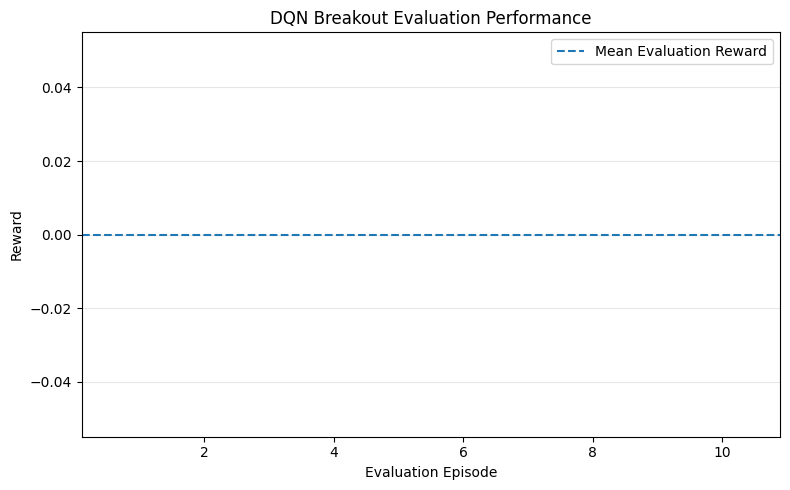

In [29]:
plt.figure(figsize=(8, 5))

episodes = np.arange(
    1,
    len(evaluation_rewards) + 1
)

plt.bar(
    episodes,
    evaluation_rewards
)

plt.axhline(
    np.mean(evaluation_rewards),
    linestyle="--",
    label="Mean Evaluation Reward"
)

plt.xlabel("Evaluation Episode")
plt.ylabel("Reward")
plt.title("DQN Breakout Evaluation Performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "evaluation_rewards.png"
    ),
    dpi=300
)

plt.show()

##Save Gameplay as a GIF

In [30]:
if len(gameplay_frames) > 0:

    gif_path = os.path.join(
        OUTPUT_DIR,
        "trained_dqn_breakout.gif"
    )

    imageio.mimsave(
        gif_path,
        gameplay_frames,
        fps=30
    )

    print(
        "Gameplay GIF saved:",
        gif_path
    )

else:
    print("No gameplay frames were recorded.")

Gameplay GIF saved: dqn_breakout_outputs/trained_dqn_breakout.gif


## Gameplay Snapshots

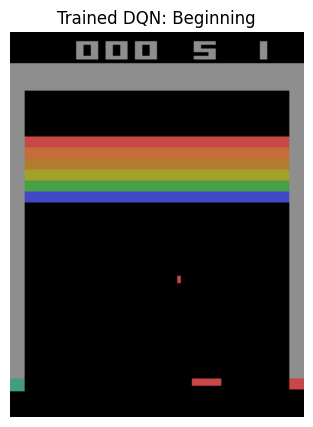

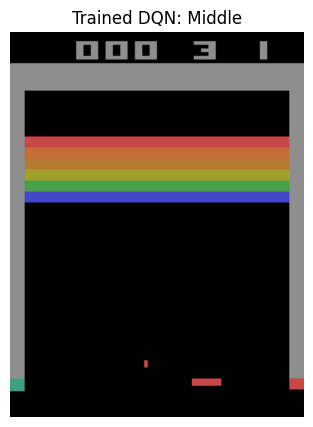

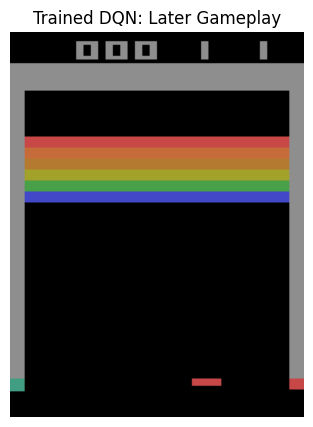

In [31]:
if len(gameplay_frames) >= 3:

    snapshot_indexes = [
        0,
        len(gameplay_frames) // 2,
        len(gameplay_frames) - 1
    ]

    titles = [
        "Beginning",
        "Middle",
        "Later Gameplay"
    ]

    for i, index in enumerate(snapshot_indexes):

        plt.figure(figsize=(5, 5))

        plt.imshow(
            gameplay_frames[index]
        )

        plt.title(
            f"Trained DQN: {titles[i]}"
        )

        plt.axis("off")

        file_name = os.path.join(
            OUTPUT_DIR,
            f"gameplay_snapshot_{i + 1}.png"
        )

        plt.savefig(
            file_name,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

else:
    print("Not enough gameplay frames for snapshots.")

##List Generated Files

In [32]:
print("Generated project files:")
print()

for file_name in sorted(
    os.listdir(OUTPUT_DIR)
):
    print(file_name)

Generated project files:

best_dqn_breakout.pt
episode_metrics.csv
episode_rewards.png
epsilon_decay.png
evaluation_rewards.png
final_dqn_breakout.pt
gameplay_snapshot_1.png
gameplay_snapshot_2.png
gameplay_snapshot_3.png
q_value_trend.png
trained_dqn_breakout.gif
training_loss.png
training_metrics.csv


# Optional Hyperparameter Experiments

To compare DQN behavior, change the values in the hyperparameter cell and retrain from scratch.

Recommended experiments:

### Experiment 1: Baseline
- Learning rate = 0.0001
- Batch size = 32
- Epsilon decay = 100,000

### Experiment 2: Higher Learning Rate
- Learning rate = 0.001
- Keep other values unchanged

### Experiment 3: Larger Batch
- Batch size = 64
- Keep other values unchanged

### Experiment 4: Faster Exploration Decay
- Epsilon decay = 50,000
- Keep other values unchanged

Compare:
- Episode rewards
- Moving-average reward
- Training loss
- Average Q-values
- Evaluation rewards

Important: recreate the agent and replay buffer before each experiment so each run starts from scratch.

## Reset Agent for a New Hyperparameter Experiment

After changing hyperparameters, run this cell before training again.

In [33]:
# Recreate the environment
env = make_atari_env()

# Recreate replay memory
replay_buffer = ReplayBuffer(
    REPLAY_BUFFER_SIZE
)

# Recreate agent with new hyperparameters
agent = DQNAgent(
    state_channels=FRAME_STACK,
    number_of_actions=env.action_space.n,
    learning_rate=LEARNING_RATE,
    device=device
)

# Reset metrics
episode_rewards = []
episode_lengths = []
episode_epsilons = []

training_losses = []
loss_steps = []

average_q_values = []
q_value_steps = []

global_step = 0
best_moving_average = float("-inf")

print("Agent, replay buffer, and metrics have been reset.")

Agent, replay buffer, and metrics have been reset.
